<style>
body { counter-reset: report-section; }
h2 { counter-reset: report-subsection; }
h2::before { counter-increment: report-section; content: counter(report-section) ". "; }
h3::before { counter-increment: report-subsection; content: counter(report-section) "." counter(report-subsection) " "; }
</style>

# Human-Caused Wildfire Ignitions in Four Portuguese Municipalities

## Inference — RQ1: Proportion of intentional ignitions

**RQ1.** Did the proportion of intentional ignitions among human-caused ignitions change significantly between the period before and after 2017 in Braga, Guimarães, Guarda and Faro?

**Tests:** confidence intervals for proportions, two-proportion z-test, chi-square test of independence, chi-square test of homogeneity.

### The logic of every hypothesis test

1. **State the hypotheses.** $H_0$ = "no difference / no change"; $H_1$ = "there is a difference".
2. **Check the assumptions** of the test (sample size, normality, equal variances).
3. **Compute the test statistic** — shown both with the formula (by hand) and with the Python library, to confirm they agree.
4. **Compute the p-value**: the probability of observing a difference at least this large *if $H_0$ were true*.
5. **Decide** at significance level $\alpha = 0.05$: if $p < 0.05$, reject $H_0$; otherwise there is not enough evidence to reject it. Then state the conclusion in words.


## Setup and data

This notebook continues from `00_scope_definition.ipynb`. It reads the dataset saved at the end of that notebook's data-preparation stage (`scoped_data_required_columns.csv`), so all notebooks use exactly the same data.

> **Before running:** in `00_scope_definition.ipynb`, uncomment the cell *"Uncomment the following lines to save the scoped data to a CSV file"* and run the notebook once. This creates `scoped_data_required_columns.csv` in the same folder.

Two cleaning decisions are applied here (and identically in the other inference notebooks):

1. **Rekindles (`REACENDIMENTO`) are removed.** A rekindle is an earlier fire flaring up again, not a new ignition.
2. **Time to first intervention** is used only from 2008 onwards (it was not recorded before) and only for plausible values (0 to 24 hours).

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway

DATA_FILE = Path("scoped_data_required_columns.csv")   # saved by 00_scope_definition.ipynb
FIGURE_FOLDER = Path("figures"); FIGURE_FOLDER.mkdir(exist_ok=True)
ALPHA = 0.05

MUNICIPALITIES = ["BRAGA", "GUIMARAES", "GUARDA", "FARO"]
MUNICIPALITIES_AREA_KM2 = {"BRAGA": 183, "GUIMARAES": 241, "GUARDA": 712, "FARO": 203}
LABELS = {"BRAGA": "Braga", "GUIMARAES": "Guimarães", "GUARDA": "Guarda", "FARO": "Faro"}
COLOURS = {"BRAGA": "#2a78d6", "GUIMARAES": "#eb6834", "GUARDA": "#1baf7a", "FARO": "#eda100"}
PERIOD_COLOURS = {"pre": "#8f8e88", "post": "#2a78d6"}

def decision(p):
    return "Reject H0" if p < ALPHA else "Do not reject H0"

scoped_data = pd.read_csv(DATA_FILE, encoding="utf-8-sig")

# Ignitions used in the inference: rekindles removed
ignitions = scoped_data[scoped_data["CAUSE"] != "REACENDIMENTO"].copy()
ignitions["ANALYSIS_YEAR"] = ignitions["ANALYSIS_YEAR"].astype(int)
valid_time = (ignitions["ANALYSIS_YEAR"] >= 2008) & ignitions["INTERVENTION_TIME_MINUTES"].between(0, 1440)
ignitions.loc[~valid_time, "INTERVENTION_TIME_MINUTES"] = np.nan

print(f"Records loaded: {len(scoped_data):,} | rekindles removed: {(scoped_data['CAUSE'] == 'REACENDIMENTO').sum():,} | ignitions used: {len(ignitions):,}")

/Users/manju/.local/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/manju/.local/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (


Records loaded: 15,534 | rekindles removed: 511 | ignitions used: 15,023


## RQ1 — Proportion of intentional ignitions (proportion tests)

**Question.** Did the proportion of intentional ignitions among human-caused ignitions (intentional + negligent) change between the period before and after 2017?

**Variable.** For each human-caused ignition, a "success" is an intentional fire. The proportion of interest is

$$\hat p = \frac{\text{number of intentional ignitions}}{\text{number of intentional + negligent ignitions}}.$$

**Choice of the pre-2017 period.** The cause-composition charts and the "% of records without a cause" table in the data-quality section showed that, before 2012, almost no ignitions in Braga and Guimarães had a determined cause (< 5%). Comparing 2001–2016 with 2018–2025 would therefore compare a small, unrepresentative group of investigated fires with most fires. The main test uses **2012–2016 vs 2018–2025** (2017 excluded); the full period 2001–2016 is reported as a sensitivity check. Each municipality is tested separately, because the municipalities behave differently.

In [2]:
human = ignitions[ignitions["CAUSE"].isin(["INTENCIONAL", "NEGLIGENTE"])].copy()
human["INTENTIONAL"] = (human["CAUSE"] == "INTENCIONAL").astype(int)

def counts(frame, years):
    sub = frame[frame["ANALYSIS_YEAR"].between(*years)]
    g = sub.groupby("MUNICIPALITY")["INTENTIONAL"].agg(x="sum", n="count").reindex(MUNICIPALITIES)
    return g

PRE, POST, PRE_FULL = (2012, 2016), (2018, 2025), (2001, 2016)
pre, post = counts(human, PRE), counts(human, POST)

rq1_table = pd.DataFrame({
    "Intentional (pre)": pre["x"], "Human-caused (pre)": pre["n"], "p̂ pre": (pre["x"] / pre["n"]).round(3),
    "Intentional (post)": post["x"], "Human-caused (post)": post["n"], "p̂ post": (post["x"] / post["n"]).round(3),
})
rq1_table.index = [LABELS[m] for m in MUNICIPALITIES]
rq1_table

,Intentional (pre),Human-caused (pre),p̂ pre,Intentional (post),Human-caused (post),p̂ post
Braga,26,124,0.210,85,133,0.639
Guimarães,19,150,0.127,167,388,0.430
Guarda,74,227,0.326,66,213,0.310
Faro,9,105,0.086,33,150,0.220


### Confidence intervals for each proportion

A 95% confidence interval gives a range of plausible values for the true proportion:

$$\hat p \pm z_{0.975}\sqrt{\frac{\hat p(1-\hat p)}{n}}, \qquad z_{0.975} = 1.96.$$

**Condition:** $n\hat p \ge 10$ and $n(1-\hat p) \ge 10$ (at least 10 successes and 10 failures). The Wilson interval is also shown; it is more reliable when a proportion is close to 0 or 1 or the sample is small.

In [3]:
z975 = stats.norm.ppf(0.975)
rows = []
for m in MUNICIPALITIES:
    for label, g in [("2012–2016", pre), ("2018–2025", post)]:
        x, n = int(g.loc[m, "x"]), int(g.loc[m, "n"])
        p = x / n
        se = np.sqrt(p * (1 - p) / n)
        wl, wu = proportion_confint(x, n, alpha=ALPHA, method="wilson")
        rows.append({"Municipality": LABELS[m], "Period": label, "x": x, "n": n, "p̂": round(p, 3),
                     "95% CI (formula)": f"[{p - z975 * se:.3f}, {p + z975 * se:.3f}]",
                     "95% CI (Wilson)": f"[{wl:.3f}, {wu:.3f}]",
                     "Condition n·p̂ ≥ 10 and n·(1−p̂) ≥ 10": "OK" if min(x, n - x) >= 10 else "NOT MET"})
ci_table = pd.DataFrame(rows).set_index(["Municipality", "Period"])
ci_table

x    n     p̂ 95% CI (formula) 95% CI (Wilson)  \
Municipality Period                                                        
Braga        2012–2016   26  124  0.210   [0.138, 0.281]  [0.147, 0.290]   
             2018–2025   85  133  0.639   [0.557, 0.721]  [0.555, 0.716]   
Guimarães    2012–2016   19  150  0.127   [0.073, 0.180]  [0.083, 0.189]   
             2018–2025  167  388  0.430   [0.381, 0.480]  [0.382, 0.480]   
Guarda       2012–2016   74  227  0.326   [0.265, 0.387]  [0.268, 0.389]   
             2018–2025   66  213  0.310   [0.248, 0.372]  [0.252, 0.375]   
Faro         2012–2016    9  105  0.086   [0.032, 0.139]  [0.046, 0.155]   
             2018–2025   33  150  0.220   [0.154, 0.286]  [0.161, 0.293]   

                       Condition n·p̂ ≥ 10 and n·(1−p̂) ≥ 10  
Municipality Period                                           
Braga        2012–2016                                    OK  
             2018–2025                                    OK  
Guimarães    2012–2016                                    OK  
             2018–2025                                    OK  
Guarda       2012–2016                                    OK  
             2018–2025                                    OK  
Faro         2012–2016                               NOT MET  
             2018–2025                                    OK

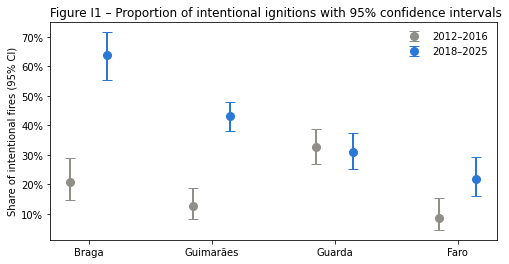

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, m in enumerate(MUNICIPALITIES):
    for j, (label, g, key) in enumerate([("2012–2016", pre, "pre"), ("2018–2025", post, "post")]):
        x, n = int(g.loc[m, "x"]), int(g.loc[m, "n"])
        lo, hi = proportion_confint(x, n, alpha=ALPHA, method="wilson")
        xpos = i + (j - 0.5) * 0.3
        ax.errorbar(xpos, x / n, yerr=[[x / n - lo], [hi - x / n]], fmt="o", ms=8, capsize=5, lw=2,
                    color=PERIOD_COLOURS[key], label=label if i == 0 else None)
ax.set_xticks(range(4), [LABELS[m] for m in MUNICIPALITIES])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylabel("Share of intentional fires (95% CI)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
ax.set_title("Figure I1 – Proportion of intentional ignitions with 95% confidence intervals", loc="left")
fig.savefig(FIGURE_FOLDER / "figI1_proportion_ci.png", dpi=200, bbox_inches="tight")
plt.show()

When the two intervals of a municipality do not overlap, this already suggests a significant difference. The formal test follows.

### Two-proportion z-test

**Hypotheses** (for each municipality, two-sided):

$$H_0: p_{\text{pre}} = p_{\text{post}} \qquad H_1: p_{\text{pre}} \ne p_{\text{post}}$$

**Test statistic.** Under $H_0$ both periods share the same proportion, estimated by the pooled proportion

$$\hat p = \frac{x_1 + x_2}{n_1 + n_2}, \qquad z = \frac{\hat p_1 - \hat p_2}{\sqrt{\hat p(1-\hat p)\left(\frac{1}{n_1} + \frac{1}{n_2}\right)}}, \qquad \text{p-value} = 2\,P(Z > |z|).$$

**Condition:** at least 10 successes and 10 failures in each group (checked above), and independent observations.

In [5]:
def two_prop_ztest(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2
    p_pool = (x1 + x2) / (n1 + n2)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se
    p_value = 2 * stats.norm.sf(abs(z))
    return p1, p2, p_pool, se, z, p_value

rows = []
for m in MUNICIPALITIES:
    x1, n1, x2, n2 = int(pre.loc[m, "x"]), int(pre.loc[m, "n"]), int(post.loc[m, "x"]), int(post.loc[m, "n"])
    p1, p2, pp, se, z, pv = two_prop_ztest(x1, n1, x2, n2)
    z_lib, pv_lib = proportions_ztest([x1, x2], [n1, n2])
    diff_lo, diff_hi = confint_proportions_2indep(x2, n2, x1, n1, method="wald")
    rows.append({"Municipality": LABELS[m], "p̂ pre": round(p1, 3), "p̂ post": round(p2, 3),
                 "pooled p̂": round(pp, 3), "SE": round(se, 4), "z (formula)": round(z, 3),
                 "z (statsmodels)": round(z_lib, 3), "p-value": f"{pv:.2g}",
                 "95% CI for p_post − p_pre": f"[{diff_lo:+.3f}, {diff_hi:+.3f}]",
                 "Decision (α = 0.05)": decision(pv)})
rq1_results = pd.DataFrame(rows).set_index("Municipality")
rq1_results

,p̂ pre,p̂ post,pooled p̂,SE,z (formula),z (statsmodels),p-value,95% CI for p_post − p_pre,Decision (α = 0.05)
Municipality,,,,,,,,,
Braga,0.210,0.639,0.432,0.0618,-6.945,-6.945,3.8e-12,"[+0.321, +0.538]",Reject H0
Guimarães,0.127,0.430,0.346,0.0457,-6.643,-6.643,3.1e-11,"[+0.231, +0.376]",Reject H0
Guarda,0.326,0.310,0.318,0.0444,0.363,0.363,0.72,"[-0.103, +0.071]",Do not reject H0
Faro,0.086,0.220,0.165,0.0472,-2.845,-2.845,0.0044,"[+0.049, +0.220]",Reject H0


**Worked example — Guarda (by hand).** $x_1 = 74,\ n_1 = 227,\ x_2 = 66,\ n_2 = 213$.

- $\hat p_1 = 74/227 = 0.326$, $\hat p_2 = 66/213 = 0.310$
- Pooled $\hat p = (74+66)/(227+213) = 140/440 = 0.318$
- $SE = \sqrt{0.318 \times 0.682 \times (1/227 + 1/213)} = 0.0444$
- $z = (0.326 - 0.310)/0.0444 = 0.36$
- p-value $= 2\,P(Z > 0.36) = 0.72 > 0.05$ → **do not reject $H_0$**.

The same steps applied to the other municipalities give the values in the table above.

### Chi-square test of independence (same question, contingency-table form)

The two-proportion test can also be written as a $2 \times 2$ contingency table (Period × Cause). The chi-square test compares the **observed** counts $O$ with the counts **expected** if period and cause were independent:

$$E = \frac{\text{row total} \times \text{column total}}{\text{grand total}}, \qquad \chi^2 = \sum \frac{(O - E)^2}{E}, \qquad df = (r-1)(c-1) = 1.$$

$H_0$: cause type (intentional/negligent) is independent of the period. $H_1$: they are associated. **Condition:** all expected counts $\ge 5$.

For a $2 \times 2$ table without continuity correction, $\chi^2 = z^2$, so the p-values must match the z-test.

In [6]:
rows = []
for m in MUNICIPALITIES:
    obs = np.array([[pre.loc[m, "x"], pre.loc[m, "n"] - pre.loc[m, "x"]],
                    [post.loc[m, "x"], post.loc[m, "n"] - post.loc[m, "x"]]])
    chi2, pv, dof, expected = stats.chi2_contingency(obs, correction=False)
    rows.append({"Municipality": LABELS[m], "χ²": round(chi2, 3),
                 "z² from z-test": round(rq1_results.loc[LABELS[m], "z (formula)"] ** 2, 3),
                 "df": dof, "p-value": f"{pv:.2g}", "min expected count": round(expected.min(), 1),
                 "Decision": decision(pv)})
pd.DataFrame(rows).set_index("Municipality")

,χ²,z² from z-test,df,p-value,min expected count,Decision
Municipality,,,,,,
Braga,48.228,48.233,1,3.8e-12,53.6,Reject H0
Guimarães,44.123,44.129,1,3.1e-11,51.9,Reject H0
Guarda,0.132,0.132,1,0.72,67.8,Do not reject H0
Faro,8.096,8.094,1,0.0044,17.3,Reject H0


In [7]:
# Detailed table for one municipality (Braga), to show observed vs expected counts
m = "BRAGA"
obs = pd.DataFrame([[pre.loc[m, "x"], pre.loc[m, "n"] - pre.loc[m, "x"]],
                    [post.loc[m, "x"], post.loc[m, "n"] - post.loc[m, "x"]]],
                   index=["2012–2016", "2018–2025"], columns=["Intentional", "Negligent"])
chi2, pv, dof, expected = stats.chi2_contingency(obs.values, correction=False)
print("Observed counts (Braga):"); display(obs)
print("Expected counts if H0 were true:"); display(pd.DataFrame(expected.round(1), index=obs.index, columns=obs.columns))
print("Contribution (O−E)²/E of each cell:"); display(((obs - expected) ** 2 / expected).round(2))
print(f"χ² = {chi2:.2f}, df = {dof}, p-value = {pv:.2g}")

Observed counts (Braga):


,Intentional,Negligent
2012–2016,26,98
2018–2025,85,48


Expected counts if H0 were true:


,Intentional,Negligent
2012–2016,53.6,70.4
2018–2025,57.4,75.6


Contribution (O−E)²/E of each cell:


,Intentional,Negligent
2012–2016,14.18,10.78
2018–2025,13.22,10.05


χ² = 48.23, df = 1, p-value = 3.8e-12


### Chi-square test of homogeneity across municipalities

A second chi-square question: **after 2017, is the share of intentional fires the same in the four municipalities?** This uses a $4 \times 2$ table (Municipality × Cause), $df = (4-1)(2-1) = 3$.

$H_0$: the proportion of intentional ignitions is the same in all four municipalities (2018–2025). $H_1$: at least one differs.

In [8]:
post_table = pd.DataFrame({"Intentional": post["x"], "Negligent": post["n"] - post["x"]})
post_table.index = [LABELS[m] for m in MUNICIPALITIES]
chi2, pv, dof, expected = stats.chi2_contingency(post_table.values)
display(post_table)
print(f"χ² = {chi2:.2f}, df = {dof}, p-value = {pv:.2g}, min expected count = {expected.min():.1f}  →  {decision(pv)}")

,Intentional,Negligent
Braga,85,48
Guimarães,167,221
Guarda,66,147
Faro,33,117


χ² = 60.76, df = 3, p-value = 4.1e-13, min expected count = 52.8  →  Reject H0


### Sensitivity check: using the full pre-2017 period (2001–2016)

In [9]:
pre_full = counts(human, PRE_FULL)
rows = []
for m in MUNICIPALITIES:
    x1, n1, x2, n2 = int(pre_full.loc[m, "x"]), int(pre_full.loc[m, "n"]), int(post.loc[m, "x"]), int(post.loc[m, "n"])
    p1, p2, _, _, z, pv = two_prop_ztest(x1, n1, x2, n2)
    rows.append({"Municipality": LABELS[m], "p̂ 2001–2016": round(p1, 3), "n": n1,
                 "p̂ 2018–2025": round(p2, 3), "n ": n2, "z": round(z, 2), "p-value": f"{pv:.2g}", "Decision": decision(pv)})
pd.DataFrame(rows).set_index("Municipality")

,p̂ 2001–2016,n,p̂ 2018–2025,n,z,p-value,Decision
Municipality,,,,,,,
Braga,0.347,173,0.639,133,-5.08,3.9e-07,Reject H0
Guimarães,0.194,180,0.430,388,-5.47,4.6e-08,Reject H0
Guarda,0.232,591,0.310,213,-2.25,0.025,Reject H0
Faro,0.074,122,0.220,150,-3.32,0.0009,Reject H0


**RQ1 conclusion (to be confirmed by the team when writing the report).**

- In **Braga, Guimarães and Faro** the proportion of intentional ignitions among human-caused ignitions is significantly higher after 2017 ($p < 0.01$); the confidence intervals do not overlap.
- In **Guarda**, the only municipality with near-complete cause investigation in both periods, the proportion did **not** change significantly (about 33% vs 31%, $p = 0.72$).
- After 2017 the share of intentional fires differs significantly among the four municipalities (chi-square test of homogeneity).
- With the full 2001–2016 period, Guarda also becomes significant, which shows how sensitive the result is to the change in investigation coverage.

**Limitation.** The proportion of ignitions with a determined cause rose strongly after 2017 in Braga, Guimarães and Faro. The tests compare *investigated* fires, so part of the change in these municipalities may reflect which fires were investigated, not a change in behaviour. Guarda, with stable coverage, is the most reliable comparison.

Inference — RQ2: Mean annual number of ignitions
RQ2. Did the mean annual number of fire ignitions differ significantly between the pre-2017 and post-2017 periods in Braga, Guimarães, Guarda and Faro?

In [10]:
# Municipality-year table (one row = one municipality in one year)
annual = (ignitions.groupby(["MUNICIPALITY", "ANALYSIS_YEAR"]).size()
          .unstack(0).reindex(columns=MUNICIPALITIES).fillna(0).astype(int))
annual_long = annual.stack().rename("IGNITIONS").reset_index()
annual_long["PERIOD"] = np.select([annual_long["ANALYSIS_YEAR"] <= 2016, annual_long["ANALYSIS_YEAR"] == 2017],
                                  ["pre", "2017"], "post")
annual_long["DENSITY"] = annual_long["IGNITIONS"] / annual_long["MUNICIPALITY"].map(MUNICIPALITIES_AREA_KM2)
annual.T

ANALYSIS_YEAR,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
MUNICIPALITY,,,,,,,,,,,,,,,,,,,,,
BRAGA,285,279,380,253,404,329,199,83,224,190,...,108,102,81,76,67,35,41,31,30,50
GUIMARAES,833,795,949,593,875,433,379,169,482,329,...,219,257,182,106,92,67,85,50,49,56
GUARDA,159,149,120,71,132,100,83,140,100,72,...,47,61,23,24,44,28,46,23,23,45
FARO,16,11,14,26,29,69,80,42,61,22,...,16,42,26,35,22,29,21,27,15,32


RQ2 — Mean annual number of ignitions (two-sample t-test)
Question. Did the mean annual number of ignitions differ between 2001–2016 ( 𝑛1=16
  years) and 2018–2025 ( 𝑛2=8
  years)?

Here one observation = one year in one municipality.

𝐻0:𝜇pre=𝜇post𝐻1:𝜇pre≠𝜇post

In [13]:
def groups(m, pre_years=(2001, 2016), post_years=(2018, 2025)):
    s = annual[m]
    return s.loc[pre_years[0]:pre_years[1]].values, s.loc[post_years[0]:post_years[1]].values

rows = []
for m in MUNICIPALITIES:
    a, b = groups(m)
    for label, g in [("2001–2016", a), ("2018–2025", b)]:
        n, mean, sd = len(g), g.mean(), g.std(ddof=1)
        t_crit = stats.t.ppf(0.975, n - 1)
        rows.append({"Municipality": LABELS[m], "Period": label, "n (years)": n, "mean": round(mean, 1),
                     "sd": round(sd, 1), "95% CI for the mean": f"[{mean - t_crit * sd / np.sqrt(n):.1f}, {mean + t_crit * sd / np.sqrt(n):.1f}]"})
pd.DataFrame(rows).set_index(["Municipality", "Period"])

n (years)   mean     sd 95% CI for the mean
Municipality Period                                                
Braga        2001–2016         16  218.0  106.9      [161.1, 274.9]
             2018–2025          8   51.4   20.6        [34.1, 68.6]
Guimarães    2001–2016         16  471.1  265.8      [329.4, 612.7]
             2018–2025          8   85.9   44.0       [49.1, 122.7]
Guarda       2001–2016         16   88.8   41.4       [66.8, 110.9]
             2018–2025          8   32.0   10.9        [22.9, 41.1]
Faro         2001–2016         16   34.6   20.2        [23.9, 45.4]
             2018–2025          8   25.9    6.4        [20.5, 31.2]

The 95% confidence interval for a mean uses the t distribution because  𝜎
  is unknown:  𝑥¯±𝑡0.975,𝑛−1𝑠𝑛⎯⎯√
 .

Checking the assumptions
The two-sample t-test assumes (1) independent samples, (2) approximately normal data in each group (important here because the samples are small), and (3) for the Student version, equal variances.

Normality — Shapiro-Wilk test.  𝐻0
 : the data come from a normal distribution.
Equal variances — Levene's test ( 𝐻0
 :  𝜎21=𝜎22
 ) and the rule of thumb used in class: the ratio of the larger to the smaller sample variance should be below 4.

In [14]:
rows = []
for m in MUNICIPALITIES:
    a, b = groups(m)
    var_ratio = max(a.var(ddof=1), b.var(ddof=1)) / min(a.var(ddof=1), b.var(ddof=1))
    rows.append({"Municipality": LABELS[m],
                 "Shapiro p (pre)": round(stats.shapiro(a).pvalue, 3),
                 "Shapiro p (post)": round(stats.shapiro(b).pvalue, 3),
                 "Levene p": round(stats.levene(a, b).pvalue, 4),
                 "variance ratio (max/min)": round(var_ratio, 1),
                 "Equal variances?": "yes" if (stats.levene(a, b).pvalue >= ALPHA and var_ratio < 4) else "no → use Welch"})
assumptions_rq2 = pd.DataFrame(rows).set_index("Municipality")
assumptions_rq2

,Shapiro p (pre),Shapiro p (post),Levene p,variance ratio (max/min),Equal variances?
Municipality,,,,,
Braga,0.968,0.190,0.0023,26.8,no → use Welch
Guimarães,0.171,0.046,0.0059,36.4,no → use Welch
Guarda,0.330,0.006,0.0073,14.4,no → use Welch
Faro,0.062,0.981,0.0694,9.9,no → use Welch


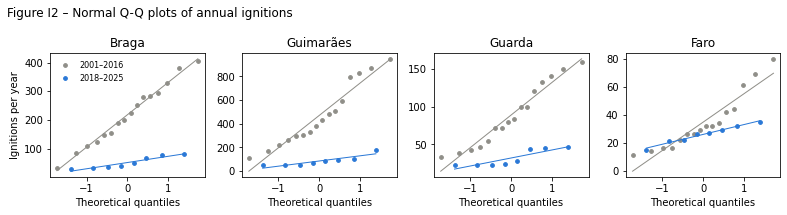

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, m in zip(axes, MUNICIPALITIES):
    a, b = groups(m)
    for g, key in [(a, "pre"), (b, "post")]:
        (osm, osr), (slope, intercept, _) = stats.probplot(g)
        ax.scatter(osm, osr, s=14, color=PERIOD_COLOURS[key], label="2001–2016" if key == "pre" else "2018–2025")
        ax.plot(osm, slope * np.array(osm) + intercept, color=PERIOD_COLOURS[key], lw=1)
    ax.set_title(LABELS[m]); ax.set_xlabel("Theoretical quantiles")
axes[0].set_ylabel("Ignitions per year"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Figure I2 – Normal Q-Q plots of annual ignitions", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIGURE_FOLDER / "figI2_qqplots.png", dpi=200, bbox_inches="tight"); plt.show()

Two-sample t-tests
Student (pooled variance):

        𝑠2𝑝=(𝑛1−1)𝑠21+(𝑛2−1)𝑠22𝑛1+𝑛2−2,𝑡=𝑥¯1−𝑥¯2𝑠𝑝1𝑛1+1𝑛2⎯⎯⎯⎯⎯⎯⎯⎯⎯⎯⎯⎯√,𝑑𝑓=𝑛1+𝑛2−2.
 

Welch (unequal variances):

        𝑡=𝑥¯1−𝑥¯2𝑠21𝑛1+𝑠22𝑛2⎯⎯⎯⎯⎯⎯⎯⎯⎯⎯⎯⎯√,𝑑𝑓=(𝑠21𝑛1+𝑠22𝑛2)2(𝑠21/𝑛1)2𝑛1−1+(𝑠22/𝑛2)2𝑛2−1.

In [16]:
def t_tests(a, b):
    n1, n2 = len(a), len(b)
    m1, m2, v1, v2 = a.mean(), b.mean(), a.var(ddof=1), b.var(ddof=1)
    sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
    t_student = (m1 - m2) / np.sqrt(sp2 * (1 / n1 + 1 / n2)); df_s = n1 + n2 - 2
    se_w = np.sqrt(v1 / n1 + v2 / n2)
    t_welch = (m1 - m2) / se_w
    df_w = se_w ** 4 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
    p_s = 2 * stats.t.sf(abs(t_student), df_s); p_w = 2 * stats.t.sf(abs(t_welch), df_w)
    ci_w = (m1 - m2 - stats.t.ppf(0.975, df_w) * se_w, m1 - m2 + stats.t.ppf(0.975, df_w) * se_w)
    return dict(diff=m1 - m2, t_s=t_student, df_s=df_s, p_s=p_s, t_w=t_welch, df_w=df_w, p_w=p_w, ci_w=ci_w)

rows = []
for m in MUNICIPALITIES:
    a, b = groups(m)
    r = t_tests(a, b)
    lib = stats.ttest_ind(a, b, equal_var=False)
    mw = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"Municipality": LABELS[m], "mean pre − post": round(r["diff"], 1),
                 "Student t": round(r["t_s"], 2), "Student p": f"{r['p_s']:.2g}",
                 "Welch t": round(r["t_w"], 2), "Welch df": round(r["df_w"], 1),
                 "Welch p (formula)": f"{r['p_w']:.2g}", "Welch p (scipy)": f"{lib.pvalue:.2g}",
                 "95% CI for difference (Welch)": f"[{r['ci_w'][0]:.1f}, {r['ci_w'][1]:.1f}]",
                 "Mann-Whitney p": f"{mw.pvalue:.2g}", "Decision (Welch)": decision(r["p_w"])})
rq2_results = pd.DataFrame(rows).set_index("Municipality")
rq2_results

,mean pre − post,Student t,Student p,Welch t,Welch df,Welch p (formula),Welch p (scipy),95% CI for difference (Welch),Mann-Whitney p,Decision (Welch)
Municipality,,,,,,,,,,
Braga,166.6,4.32,0.00027,6.02,17.1,1.3e-05,1.3e-05,"[108.2, 225.0]",8.2e-05,Reject H0
Guimarães,385.2,4.03,0.00056,5.64,16.6,3.2e-05,3.2e-05,"[240.9, 529.5]",1.1e-05,Reject H0
Guarda,56.8,3.78,0.001,5.15,18.7,6e-05,6e-05,"[33.7, 79.9]",0.00083,Reject H0
Faro,8.8,1.18,0.25,1.58,19.9,0.13,0.13,"[-2.8, 20.3]",0.44,Do not reject H0


Sensitivity check: the decline had already started before 2017
The annual line plot in the exploration showed a downward trend in Braga, Guimarães and Guarda well before 2017. To check that the result is not only due to the high counts of the early 2000s, the test is repeated using only the years just before 2017 (2012–2016,  𝑛1=5
 ).

In [17]:
rows = []
for m in MUNICIPALITIES:
    a, b = groups(m, pre_years=(2012, 2016))
    r = t_tests(a, b)
    rows.append({"Municipality": LABELS[m], "mean 2012–2016": round(a.mean(), 1), "mean 2018–2025": round(b.mean(), 1),
                 "Welch t": round(r["t_w"], 2), "Welch df": round(r["df_w"], 1), "Welch p": f"{r['p_w']:.2g}",
                 "Mann-Whitney p": f"{stats.mannwhitneyu(a, b).pvalue:.2g}", "Decision": decision(r["p_w"])})
pd.DataFrame(rows).set_index("Municipality")

,mean 2012–2016,mean 2018–2025,Welch t,Welch df,Welch p,Mann-Whitney p,Decision
Municipality,,,,,,,
Braga,113.8,51.4,2.73,4.9,0.042,0.045,Reject H0
Guimarães,239.2,85.9,3.89,5.5,0.0096,0.0031,Reject H0
Guarda,51.4,32.0,2.24,6.0,0.066,0.047,Do not reject H0
Faro,31.6,25.9,1.14,6.1,0.3,0.21,Do not reject H0


RQ2 conclusion (to be confirmed with team).

The mean annual number of ignitions was significantly lower after 2017 in Braga, Guimarães and Guarda (Welch t-test,  𝑝<0.001
 ; confirmed by Mann-Whitney).
In Faro there is no significant difference ( 𝑝>0.05
 ): Faro had few ignitions in both periods.
When only the years just before 2017 are used (2012–2016 vs 2018–2025), the difference stays significant in Braga ( 𝑝=0.04
 ) and Guimarães ( 𝑝=0.01
 ), but in Guarda it becomes borderline (Welch  𝑝=0.07
 , Mann-Whitney  𝑝=0.047
 ) and Faro stays non-significant. With only 5 years before 2017 the evidence is naturally weaker.
Limitation: the decline was already under way before 2017, so the test shows that ignitions are lower after 2017, not that 2017 caused the decrease.

Additional test — Time to first intervention before and after 2017
So that a per-fire quantitative variable is also used in inference: did the time from alert to first intervention change after 2017? This variable is available from 2008, so the comparison is 2008–2016 vs 2018–2025.

𝐻0: the distribution of intervention times is the same in both periods.  
𝐻1: it differs.

In [18]:
rows = []
for m in MUNICIPALITIES:
    sub = ignitions[ignitions["MUNICIPALITY"] == m]
    a = sub.loc[sub["ANALYSIS_YEAR"].between(2008, 2016), "INTERVENTION_TIME_MINUTES"].dropna()
    b = sub.loc[sub["ANALYSIS_YEAR"].between(2018, 2025), "INTERVENTION_TIME_MINUTES"].dropna()
    mw = stats.mannwhitneyu(a, b, alternative="two-sided")
    w = stats.ttest_ind(a, b, equal_var=False)
    rows.append({"Municipality": LABELS[m], "n pre": len(a), "median pre (min)": a.median(), "n post": len(b),
                 "median post (min)": b.median(), "mean pre": round(a.mean(), 1), "mean post": round(b.mean(), 1),
                 "Mann-Whitney p": f"{mw.pvalue:.2g}", "Welch t p": f"{w.pvalue:.2g}", "Decision (Mann-Whitney)": decision(mw.pvalue)})
pd.DataFrame(rows).set_index("Municipality")

,n pre,median pre (min),n post,median post (min),mean pre,mean post,Mann-Whitney p,Welch t p,Decision (Mann-Whitney)
Municipality,,,,,,,,,
Braga,1307,10.0,410,14.0,11.3,14.7,9.3e-18,6e-12,Reject H0
Guimarães,2575,10.0,686,12.0,10.9,15.3,1.3e-21,9e-15,Reject H0
Guarda,557,13.0,252,14.0,16.4,16.0,0.13,0.72,Do not reject H0
Faro,301,9.0,207,11.0,10.0,10.9,0.0026,0.051,Reject H0


Inference — RQ3: Mean annual number of ignitions across municipalities
RQ3. Did the mean annual number of fire ignitions differ significantly among Braga, Guimarães, Guarda and Faro?

Tests: one-way ANOVA (table by hand), Levene and Shapiro-Wilk (assumptions), Welch ANOVA, Kruskal-Wallis, Tukey HSD and Games-Howell post-hoc tests, the same ANOVA on ignition density as a check, and a two-way ANOVA (municipality × period) as an extension.

The logic of every hypothesis test
State the hypotheses.  𝐻0
  = "no difference / no change";  𝐻1
  = "there is a difference".
Check the assumptions of the test (sample size, normality, equal variances).
Compute the test statistic — shown both with the formula (by hand) and with the Python library, to confirm they agree.
Compute the p-value: the probability of observing a difference at least this large if  𝐻0
  were true.
Decide at significance level  𝛼=0.05
 : if  𝑝<0.05
 , reject  𝐻0
 ; otherwise there is not enough evidence to reject it. Then state the conclusion in words

RQ3 — Mean annual number of ignitions across municipalities (one-way ANOVA)
Question. Did the mean annual number of fire ignitions differ significantly among Braga, Guimarães, Guarda and Faro over the study period?

One observation = one municipality-year (2001–2025,  𝑛=25
  per municipality,  𝑁=100). Because Guarda is about 3.5 times larger than the other municipalities, the same test is repeated on the ignition density (ignitions per km² per year) as a complementary check at the end of this section.

    𝐻0:𝜇Braga=𝜇Guimarães=𝜇Guarda=𝜇Faro𝐻1:at least one mean is different
 



In [19]:
rq3_groups = {m: annual_long.loc[annual_long["MUNICIPALITY"] == m, "IGNITIONS"].values for m in MUNICIPALITIES}
desc3 = pd.DataFrame({LABELS[m]: {"n": len(g), "mean": g.mean(), "sd": g.std(ddof=1), "variance": g.var(ddof=1),
                                  "median": np.median(g), "min": g.min(), "max": g.max()} for m, g in rq3_groups.items()}).T
desc3.round(3)

,n,mean,sd,variance,median,min,max
Braga,25.0,160.04,116.523,13577.707,124.0,30.0,404.0
Guimarães,25.0,339.24,279.280,77997.357,264.0,49.0,949.0
Guarda,25.0,69.52,42.718,1824.843,55.0,23.0,159.0
Faro,25.0,32.12,16.966,287.860,29.0,11.0,80.0


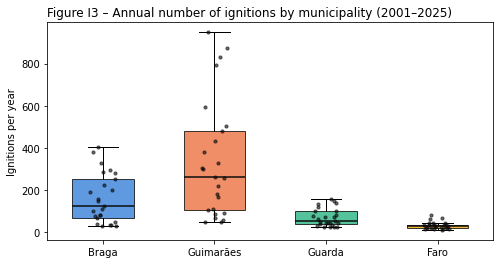

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot([rq3_groups[m] for m in MUNICIPALITIES], tick_labels=[LABELS[m] for m in MUNICIPALITIES],
                patch_artist=True, widths=0.55, showfliers=False, medianprops=dict(color="#0b0b0b", lw=1.5))
for patch, m in zip(bp["boxes"], MUNICIPALITIES):
    patch.set_facecolor(COLOURS[m]); patch.set_alpha(0.75)
rng = np.random.default_rng(1)
for i, m in enumerate(MUNICIPALITIES, start=1):
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(rq3_groups[m])), rq3_groups[m], s=10, color="#0b0b0b", alpha=0.6, zorder=3)
ax.set_ylabel("Ignitions per year"); ax.grid(axis="x", visible=False)
ax.set_title("Figure I3 – Annual number of ignitions by municipality (2001–2025)", loc="left")
fig.savefig(FIGURE_FOLDER / "figI3_annual_ignitions_box.png", dpi=200, bbox_inches="tight"); plt.show()

The ANOVA table, step by step
ANOVA splits the total variation of the data into variation between groups (differences among the municipality means) and variation within groups (year-to-year variation inside each municipality):

In [21]:
def anova_table(group_dict):
    gs = list(group_dict.values())
    k, N = len(gs), sum(len(g) for g in gs)
    grand_mean = np.concatenate(gs).mean()
    ssb = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in gs)
    ssw = sum(((g - g.mean()) ** 2).sum() for g in gs)
    dfb, dfw = k - 1, N - k
    msb, msw = ssb / dfb, ssw / dfw
    F = msb / msw
    p = stats.f.sf(F, dfb, dfw)
    table = pd.DataFrame({"Sum of squares": [ssb, ssw, ssb + ssw], "df": [dfb, dfw, N - 1],
                          "Mean square": [msb, msw, np.nan], "F": [F, np.nan, np.nan], "p-value": [p, np.nan, np.nan]},
                         index=["Between groups (municipality)", "Within groups (residual)", "Total"])
    return table, F, p

table, F, p = anova_table(rq3_groups)
display(table.round(4))
lib = stats.f_oneway(*rq3_groups.values())
print(f"Formula:  F = {F:.2f}, p = {p:.2g}")
print(f"scipy:    F = {lib.statistic:.2f}, p = {lib.pvalue:.2g}")
print(f"Critical value F(0.95; {table.loc['Between groups (municipality)', 'df']:.0f}, {table.loc['Within groups (residual)', 'df']:.0f}) = "
      f"{stats.f.ppf(0.95, 3, 96):.2f}  →  {decision(p)}")

,Sum of squares,df,Mean square,F,p-value
Between groups (municipality),1407127.31,3,469042.4367,20.0258,0.0
Within groups (residual),2248506.40,96,23421.9417,NaN,NaN
Total,3655633.71,99,NaN,NaN,NaN


Formula:  F = 20.03, p = 3.7e-10
scipy:    F = 20.03, p = 3.7e-10
Critical value F(0.95; 3, 96) = 2.70  →  Reject H0


Checking the ANOVA assumptions
ANOVA assumes (1) independent observations, (2) approximately normal residuals in each group, and (3) equal variances in all groups (homoscedasticity).

In [22]:
resid = np.concatenate([g - g.mean() for g in rq3_groups.values()])
rows = [{"Group": LABELS[m], "Shapiro-Wilk p": round(stats.shapiro(g).pvalue, 4), "variance": round(g.var(ddof=1), 4)}
        for m, g in rq3_groups.items()]
display(pd.DataFrame(rows).set_index("Group"))
print(f"Shapiro-Wilk on all residuals: p = {stats.shapiro(resid).pvalue:.2g}")
print(f"Levene test (equal variances): p = {stats.levene(*rq3_groups.values()).pvalue:.2g}")
v = [g.var(ddof=1) for g in rq3_groups.values()]
print(f"Largest / smallest variance = {max(v) / min(v):.0f}")

,Shapiro-Wilk p,variance
Group,,
Braga,0.0225,13577.7067
Guimarães,0.0048,77997.3567
Guarda,0.0109,1824.8433
Faro,0.0037,287.8600


Shapiro-Wilk on all residuals: p = 1e-08
Levene test (equal variances): p = 8.1e-10
Largest / smallest variance = 271


The variances are very different (Guimarães and Braga vary much more than Guarda and Faro) and normality is doubtful in some groups. The classical ANOVA result is therefore confirmed with tests that do not need these assumptions:

Welch's ANOVA — does not assume equal variances.
Kruskal-Wallis test — non-parametric (compares the distributions of ranks), does not assume normality.
ANOVA on log(annual ignitions) — the log transformation makes the variances much more similar.

In [23]:
welch = anova_oneway(list(rq3_groups.values()), use_var="unequal")
kw = stats.kruskal(*rq3_groups.values())
log_groups = {m: np.log(g) for m, g in rq3_groups.items()}
log_anova = stats.f_oneway(*log_groups.values())
pd.DataFrame({
    "Statistic": [lib.statistic, welch.statistic, kw.statistic, log_anova.statistic],
    "p-value": [f"{lib.pvalue:.2g}", f"{welch.pvalue:.2g}", f"{kw.pvalue:.2g}", f"{log_anova.pvalue:.2g}"],
    "Levene p (equal variances)": [f"{stats.levene(*rq3_groups.values()).pvalue:.2g}", "not required", "not required",
                                   f"{stats.levene(*log_groups.values()).pvalue:.2g}"],
    "Decision": [decision(x) for x in [lib.pvalue, welch.pvalue, kw.pvalue, log_anova.pvalue]],
}, index=["Classical one-way ANOVA (F)", "Welch ANOVA (F)", "Kruskal-Wallis (H)", "One-way ANOVA on log(annual ignitions)"])

,Statistic,p-value,Levene p (equal variances),Decision
Classical one-way ANOVA (F),20.025771,3.7e-10,8.1e-10,Reject H0
Welch ANOVA (F),23.470824,3.2e-09,not required,Reject H0
Kruskal-Wallis (H),54.394031,9.2e-12,not required,Reject H0
One-way ANOVA on log(annual ignitions),36.427586,8.3e-16,0.0022,Reject H0


Post-hoc tests: which municipalities differ?
ANOVA only says that at least one mean is different. Post-hoc tests compare every pair of municipalities (6 pairs) while controlling the overall error rate:

Tukey HSD — the standard post-hoc test; assumes equal variances.
Games-Howell — the version for unequal variances (appropriate here).

In [24]:
tukey = pairwise_tukeyhsd(annual_long["IGNITIONS"], annual_long["MUNICIPALITY"].map(LABELS), alpha=ALPHA)
print("Tukey HSD")
print(tukey.summary())

def games_howell(group_dict):
    names = list(group_dict); k = len(names); out = []
    for i in range(k):
        for j in range(i + 1, k):
            a, b = group_dict[names[i]], group_dict[names[j]]
            va, vb, na, nb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b), len(a), len(b)
            se = np.sqrt(va + vb)
            df_ = (va + vb) ** 2 / (va ** 2 / (na - 1) + vb ** 2 / (nb - 1))
            q = abs(a.mean() - b.mean()) / se * np.sqrt(2)
            p = stats.studentized_range.sf(q, k, df_)
            out.append({"Pair": f"{LABELS[names[i]]} – {LABELS[names[j]]}", "mean difference": round(a.mean() - b.mean(), 3),
                        "p-value (Games-Howell)": f"{p:.2g}", "Decision": decision(p)})
    return pd.DataFrame(out).set_index("Pair")

print("\nGames-Howell (unequal variances)")
games_howell(rq3_groups)

Tukey HSD
   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
group1   group2  meandiff p-adj    lower    upper   reject
----------------------------------------------------------
 Braga      Faro  -127.92 0.0202 -241.0982 -14.7418   True
 Braga    Guarda   -90.52 0.1634 -203.6982  22.6582  False
 Braga Guimarães    179.2 0.0004   66.0218 292.3782   True
  Faro    Guarda     37.4 0.8233  -75.7782 150.5782  False
  Faro Guimarães   307.12    0.0  193.9418 420.2982   True
Guarda Guimarães   269.72    0.0  156.5418 382.8982   True
----------------------------------------------------------

Games-Howell (unequal variances)


,mean difference,p-value (Games-Howell),Decision
Pair,,,
Braga – Guimarães,-179.20,0.028,Reject H0
Braga – Guarda,90.52,0.0052,Reject H0
Braga – Faro,127.92,6.9e-05,Reject H0
Guimarães – Guarda,269.72,0.00036,Reject H0
Guimarães – Faro,307.12,6.6e-05,Reject H0
Guarda – Faro,37.40,0.0016,Reject H0


Reading the post-hoc results. Games-Howell finds that all six pairs of municipalities differ significantly. Tukey agrees on four pairs but does not find a difference for Braga vs Guarda and Guarda vs Faro.

The reason is that Tukey uses one pooled variance for all groups. That pooled value is dominated by the large year-to-year variation of Guimarães and Braga, so it is far too large for the stable municipalities (Guarda, Faro) and hides their differences. Because the equal-variance assumption is clearly violated (Levene  𝑝<0.001
 ), the Games-Howell results are the ones to report.

Ignition density (ignitions per km² per year)
The municipalities have different areas (Braga 183 km², Guimarães 241 km², Guarda 712 km², Faro 203 km²), so a large municipality could have more fires simply because it is larger. Repeating the ANOVA on the density shows whether the conclusion holds after accounting for size.

In [25]:
density_groups = {m: annual_long.loc[annual_long["MUNICIPALITY"] == m, "DENSITY"].values for m in MUNICIPALITIES}
display(pd.DataFrame({LABELS[m]: {"mean density": g.mean(), "sd": g.std(ddof=1)} for m, g in density_groups.items()}).T.round(3))
d_anova = stats.f_oneway(*density_groups.values())
d_welch = anova_oneway(list(density_groups.values()), use_var="unequal")
d_kw = stats.kruskal(*density_groups.values())
print(f"One-way ANOVA: F = {d_anova.statistic:.2f}, p = {d_anova.pvalue:.2g}  →  {decision(d_anova.pvalue)}")
print(f"Welch ANOVA:   F = {d_welch.statistic:.2f}, p = {d_welch.pvalue:.2g}  →  {decision(d_welch.pvalue)}")
print(f"Kruskal-Wallis: H = {d_kw.statistic:.2f}, p = {d_kw.pvalue:.2g}  →  {decision(d_kw.pvalue)}")
print("\nGames-Howell on density:")
games_howell(density_groups)

,mean density,sd
Braga,0.875,0.637
Guimarães,1.408,1.159
Guarda,0.098,0.060
Faro,0.158,0.084


One-way ANOVA: F = 22.18, p = 5.4e-11  →  Reject H0
Welch ANOVA:   F = 24.12, p = 1.3e-09  →  Reject H0
Kruskal-Wallis: H = 69.54, p = 5.4e-15  →  Reject H0

Games-Howell on density:


,mean difference,p-value (Games-Howell),Decision
Pair,,,
Braga – Guimarães,-0.533,0.2,Do not reject H0
Braga – Guarda,0.777,1.5e-05,Reject H0
Braga – Faro,0.716,4.9e-05,Reject H0
Guimarães – Guarda,1.310,4.5e-05,Reject H0
Guimarães – Faro,1.249,8.7e-05,Reject H0
Guarda – Faro,-0.061,0.026,Reject H0


The conclusion does not change: the municipalities differ also per km². The ranking changes, however: per km², Guarda has the lowest ignition density (it is large but sparsely populated), while Guimarães and Braga remain far above the others.

Extension: two-way ANOVA (municipality × period)
The main research question asks whether ignitions changed after 2017 across the four municipalities. A two-way ANOVA tests three hypotheses at once on log(annual ignitions), 2017 excluded:

Municipality effect — do the municipalities differ?
Period effect — is the level different after 2017?
Interaction — did the change after 2017 differ between municipalities?
The log scale is used because the decrease is proportional (e.g. −75%) rather than a fixed number of fires, and because it stabilises the variances.

In [26]:
two_way_data = annual_long[annual_long["PERIOD"] != "2017"].copy()
two_way_data["LOG_IGNITIONS"] = np.log(two_way_data["IGNITIONS"])
two_way_data["MUNICIPALITY"] = two_way_data["MUNICIPALITY"].map(LABELS)
model = smf.ols("LOG_IGNITIONS ~ C(MUNICIPALITY) * C(PERIOD)", data=two_way_data).fit()
two_way = sm.stats.anova_lm(model, typ=2)
two_way["Decision"] = [decision(p) if not np.isnan(p) else "" for p in two_way["PR(>F)"]]
display(two_way.round(4))

ratio = (annual.loc[2018:2025].mean() / annual.loc[2001:2016].mean()).rename(index=LABELS)
print("Mean ignitions after 2017 as a share of before (post / pre):")
print((ratio * 100).round(0).astype(int).astype(str).add("%").to_string())

,sum_sq,df,F,PR(>F),Decision
C(MUNICIPALITY),59.6832,3.0,71.0751,0.0000,Reject H0
C(PERIOD),22.5982,1.0,80.7348,0.0000,Reject H0
C(MUNICIPALITY):C(PERIOD),6.5006,3.0,7.7414,0.0001,Reject H0
Residual,24.6318,88.0,NaN,NaN,


Mean ignitions after 2017 as a share of before (post / pre):
MUNICIPALITY
Braga        24%
Guimarães    18%
Guarda       36%
Faro         75%


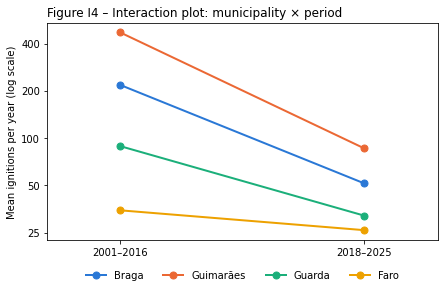

In [27]:
fig, ax = plt.subplots(figsize=(7, 4))
means = two_way_data.groupby(["MUNICIPALITY", "PERIOD"])["IGNITIONS"].mean().unstack()[["pre", "post"]]
for m in MUNICIPALITIES:
    ax.plot([0, 1], means.loc[LABELS[m]], marker="o", lw=2, ms=7, color=COLOURS[m], label=LABELS[m])
ax.set_yscale("log"); ax.set_xticks([0, 1], ["2001–2016", "2018–2025"]); ax.set_xlim(-0.3, 1.3)
ax.set_ylabel("Mean ignitions per year (log scale)"); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_locator(mticker.FixedLocator([25, 50, 100, 200, 400])); ax.yaxis.set_minor_locator(mticker.NullLocator()); ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title("Figure I4 – Interaction plot: municipality × period", loc="left")
fig.savefig(FIGURE_FOLDER / "figI4_interaction.png", dpi=200, bbox_inches="tight"); plt.show()

Non-parallel lines in the interaction plot correspond to a significant interaction: the lines for Guimarães and Braga fall much more steeply than the line for Faro.

RQ3 conclusion (to be confirmed by the team).

The mean annual number of ignitions differs significantly among the four municipalities (one-way ANOVA  𝑝<0.001
 ; confirmed by Welch ANOVA, Kruskal-Wallis and ANOVA on the log scale, since the equal-variance assumption is violated).
Games-Howell post-hoc tests show that every pair of municipalities differs (Guimarães > Braga > Guarda > Faro in mean annual ignitions).
The result also holds per km² (ignition density), where the Dense/North municipalities (Guimarães, Braga) are far above Guarda and Faro.
The two-way ANOVA shows significant municipality and period effects and a significant interaction: ignitions fell after 2017 in all municipalities, but much more in Guimarães and Braga than in Faro.